## MLPI Textbook — Chapter 5 companion notebook

# Compressing and Grouping Machine Data

### Principal component analysis, linear discriminant analysis, and k-means clustering

---

Machines produce many correlated signals. The wrist-gearbox monitor from Chapter 4 already
reduces each recording to 13 indicators, and a modern drive can stream hundreds more. Two
questions come up again and again:

* **Can we describe the machine with fewer numbers** — for a dashboard, for a model that must
  run on a PLC, or simply to *see* the data? That is **dimensionality reduction**.
* **Without labels, which operating modes does the machine actually run in?** That is
  **clustering**.

This notebook answers the first with **PCA** (unsupervised) and **LDA** (supervised) on the
gearbox data, and the second with **k-means** on the cycle log of a robot work cell.

### What you will be able to do afterwards

1. Compute principal components step by step (standardise → covariance → eigenvectors), and
   with scikit-learn; read explained variance and loadings.
2. Compute linear discriminants step by step (scatter matrices), and with scikit-learn; explain
   when LDA beats PCA and why.
3. Implement k-means from scratch, then use scikit-learn's k-means++.
4. Choose the number of clusters with the elbow method and silhouette analysis.

| § | topic |
|---|---|
| 1 | the gearbox data again |
| 2 | PCA step by step |
| 3 | PCA in scikit-learn, loadings |
| 4 | LDA step by step |
| 5 | LDA in scikit-learn; PCA vs LDA as preprocessing |
| 6 | k-means on a robot cell's cycle log |
| 7 | how many clusters? |

In [1]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("python      ", sys.version.split()[0])
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)

# plot style shared by every chapter of the book
plt.rcParams.update({
    "figure.figsize": (9, 3.6), "figure.dpi": 110,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e1e0d9",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "font.size": 10, "legend.frameon": False,
})
BLUE, ORANGE, AQUA, YELLOW, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#898781"
CLASS_COLORS = [BLUE, ORANGE, AQUA]

RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True)


def savefig(name):
    """Save the current figure for the chapter text (figures/<name>.png)."""
    plt.savefig(f"figures/{name}.png", dpi=160, bbox_inches="tight")

python       3.13.18
numpy        2.5.3
pandas       3.0.5
scikit-learn 1.9.1


---
## 1. The gearbox data again

Same generator as Chapter 4 (healthy / bearing wear / gear tooth wear; 13 indicators). The
generator is repeated here so this notebook runs on its own.

In [2]:
FAULT_NAMES = ["healthy", "bearing wear", "gear tooth wear"]
GEAR_FEATURES = ["rms_g", "peak_g", "crest_factor", "kurtosis", "skewness",
                 "e_1x", "e_2x", "e_gmf", "e_sideband", "e_bearing", "e_hf_envelope",
                 "motor_current_A", "housing_temp_C"]


def make_gearbox_dataset(n_per_class=160, seed=11):
    """Condition-monitoring snapshots from the wrist gearbox of a 6-axis robot.

    Each row summarises one 2-second accelerometer + drive-current recording
    taken while the joint runs a test move. Label `condition`:
    0 = healthy, 1 = bearing outer-race wear, 2 = gear tooth wear.
    """
    rng = np.random.default_rng(seed)
    frames = []
    for label in (0, 1, 2):
        n = n_per_class
        load = rng.uniform(0.2, 1.0, n)                 # fraction of rated torque
        speed = rng.uniform(0.3, 1.0, n)                # fraction of rated speed
        sev = np.zeros(n) if label == 0 else rng.beta(2.0, 1.6, n)   # 0 = incipient, 1 = severe
        bear = sev if label == 1 else np.zeros(n)
        gear = sev if label == 2 else np.zeros(n)
        ln = lambda s: rng.lognormal(0.0, s, n)          # multiplicative sensor/process noise

        e_1x = (0.30 + 0.25 * speed) * ln(0.25)
        e_2x = (0.12 + 0.08 * speed + 0.20 * gear) * ln(0.30)
        e_gmf = (0.50 + 0.60 * load * speed + 0.55 * gear) * ln(0.22)
        e_side = (0.06 + 0.04 * load + 0.42 * gear**1.3) * ln(0.35)
        e_bear = (0.05 + 0.03 * speed + 0.50 * bear**1.2) * ln(0.35)
        e_hf = (0.10 + 0.05 * speed + 0.35 * bear + 0.08 * gear) * ln(0.30)
        rms = np.sqrt(e_1x + e_2x + e_gmf + e_side + e_bear + e_hf)
        kurt = 3.0 + 4.5 * bear**1.5 + 1.2 * gear + rng.gamma(2.0, 0.25, n)
        crest = 2.9 + 0.55 * (kurt - 3.0) + rng.normal(0, 0.25, n)
        peak = crest * rms
        skew = rng.normal(0, 0.12, n) + 0.30 * bear - 0.10 * gear
        current = (2.0 + 4.5 * load + 0.25 * speed + 0.35 * gear) * ln(0.05)
        temp = 34 + 14 * load * speed + 3.0 * bear + 4.0 * gear + rng.normal(0, 2.2, n)
        frames.append(pd.DataFrame(dict(
            rms_g=rms, peak_g=peak, crest_factor=crest, kurtosis=kurt, skewness=skew,
            e_1x=e_1x, e_2x=e_2x, e_gmf=e_gmf, e_sideband=e_side, e_bearing=e_bear,
            e_hf_envelope=e_hf, motor_current_A=current, housing_temp_C=temp,
            condition=label)))
    df = pd.concat(frames, ignore_index=True)
    return df.sample(frac=1.0, random_state=seed).reset_index(drop=True)


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

gb = make_gearbox_dataset()
X = gb[GEAR_FEATURES].to_numpy(); y = gb["condition"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)

sc = StandardScaler().fit(X_train)
X_train_std, X_test_std = sc.transform(X_train), sc.transform(X_test)
print(X_train_std.shape, X_test_std.shape)

(336, 13) (144, 13)


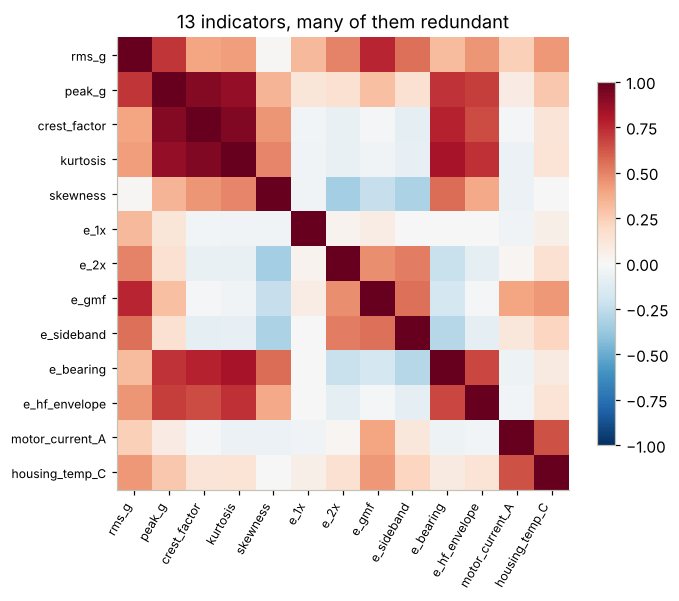

In [3]:
C = np.corrcoef(X_train_std.T)
fig, ax = plt.subplots(figsize=(6.4, 5.4))
im = ax.imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(13), GEAR_FEATURES, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(13), GEAR_FEATURES, fontsize=8); ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8); ax.set_title("13 indicators, many of them redundant")
plt.tight_layout(); savefig("ch05_corr"); plt.show()

Large blocks of strong correlation: RMS, peak, crest factor and kurtosis all respond to the same
impacts; mesh energy, current and temperature all follow load. Thirteen columns carry far fewer
than thirteen independent pieces of information. PCA finds out how many.

---
## 2. PCA step by step

PCA finds orthogonal directions — **principal components** — along which the data varies most.
For standardised data $X$ ($n \times d$):

1. compute the covariance matrix $\Sigma = \frac{1}{n-1}X^\top X$ ($d\times d$);
2. eigen-decompose it, $\Sigma\mathbf v_j = \lambda_j\mathbf v_j$;
3. sort eigenvalues in decreasing order; eigenvector $\mathbf v_1$ is the direction of largest
   variance, $\lambda_1$ that variance;
4. stack the first $k$ eigenvectors into $W$ ($d\times k$) and project: $Z = XW$.

The **explained-variance ratio** of component $j$ is $\lambda_j / \sum_i\lambda_i$.

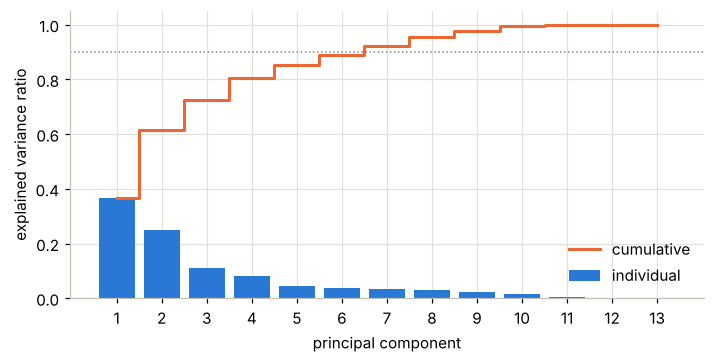

eigenvalues: [4.77 3.26 1.42 1.06 0.6  0.49 0.43 0.41 0.31 0.22 0.07 0.   0.  ]
first 2 PCs: 61.6% of variance;  components needed for 90 %: 7


In [4]:
cov = np.cov(X_train_std.T)
eig_vals, eig_vecs = np.linalg.eigh(cov)          # eigh: for symmetric matrices, ascending order
order = np.argsort(eig_vals)[::-1]
eig_vals, eig_vecs = eig_vals[order], eig_vecs[:, order]

ratio = eig_vals / eig_vals.sum()
cum = np.cumsum(ratio)
fig, ax = plt.subplots(figsize=(6.6, 3.4))
ax.bar(range(1, 14), ratio, color=BLUE, label="individual")
ax.step(range(1, 14), cum, where="mid", color=ORANGE, lw=2, label="cumulative")
ax.axhline(0.9, color=MUTED, ls=":", lw=1)
ax.set_xlabel("principal component"); ax.set_ylabel("explained variance ratio"); ax.legend()
ax.set_xticks(range(1, 14))
plt.tight_layout(); savefig("ch05_explained_variance"); plt.show()
print("eigenvalues:", eig_vals.round(2))
print(f"first 2 PCs: {cum[1]:.1%} of variance;  components needed for 90 %: {np.searchsorted(cum, 0.9) + 1}")

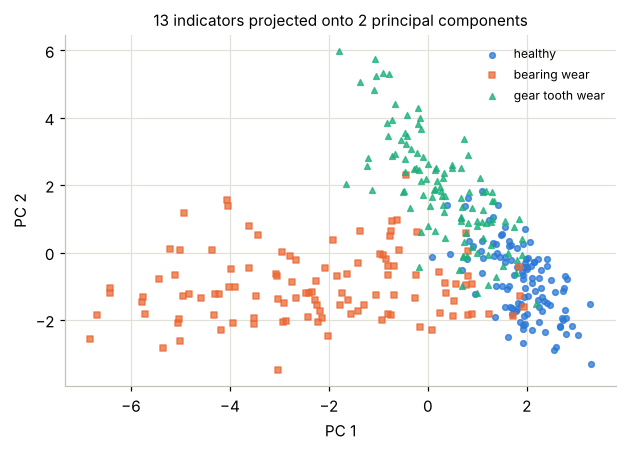

In [5]:
W = eig_vecs[:, :2]
Z_train = X_train_std @ W

fig, ax = plt.subplots(figsize=(5.8, 4.2))
for c, m in zip(range(3), ["o", "s", "^"]):
    ax.scatter(Z_train[y_train == c, 0], Z_train[y_train == c, 1], s=14, marker=m,
               color=CLASS_COLORS[c], alpha=0.75, label=FAULT_NAMES[c])
ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); ax.legend(fontsize=8)
ax.set_title("13 indicators projected onto 2 principal components", fontsize=10)
plt.tight_layout(); savefig("ch05_pca_scatter"); plt.show()

(The sign of an eigenvector is arbitrary, so your plot may be mirrored; that changes nothing.)
Remember that PCA **never saw the labels**. It still pulls the two fault types apart along
different directions, because faults are what create most of the variance. But healthy units
and incipient faults overlap near the origin: the directions of *largest variance* are not
necessarily the directions that best *separate classes*. Hold that thought until §4.

---
## 3. PCA in scikit-learn, and loadings

In [6]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2).fit(X_train_std)
print("explained variance ratio:", pca.explained_variance_ratio_.round(4))
print("matches the manual eigenvalues:", np.allclose(pca.explained_variance_ratio_, ratio[:2]))
# eigenvectors are defined only up to sign, so compare absolute values
print("same directions (up to sign):  ", np.allclose(np.abs(pca.components_.T), np.abs(W)))

explained variance ratio: [0.3657 0.2499]
matches the manual eigenvalues: True
same directions (up to sign):   True


**Loadings** tell you what a component *means*. The loading of feature $j$ on component $k$
is $v_{jk}\sqrt{\lambda_k}$ — the correlation between the original (standardised) feature and the
component score.

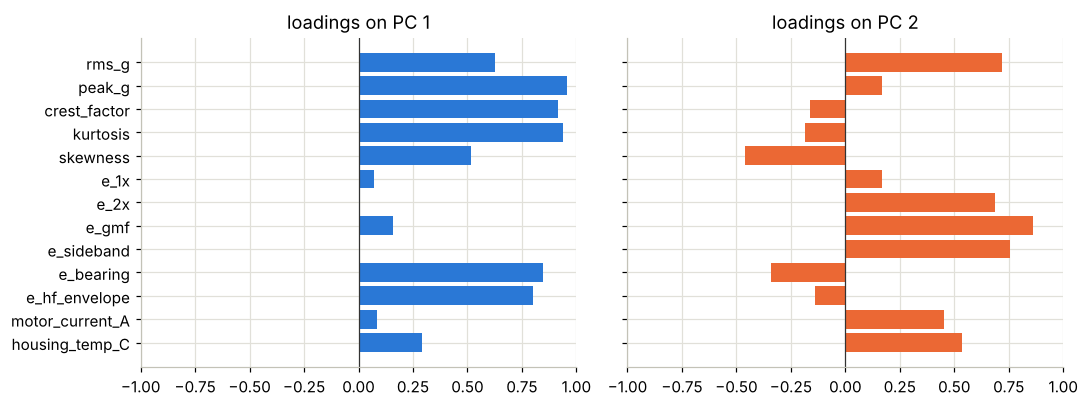

In [7]:
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for k in range(2):
    ax[k].barh(GEAR_FEATURES, loadings[:, k], color=[BLUE, ORANGE][k])
    ax[k].axvline(0, color="#333", lw=0.8); ax[k].set_title(f"loadings on PC {k + 1}")
    ax[k].set_xlim(-1, 1)
ax[0].invert_yaxis()
plt.tight_layout(); savefig("ch05_loadings"); plt.show()

Read the bars as a vibration analyst would: one component gathers the **impact / bearing**
indicators (kurtosis, crest factor, peak, bearing band, HF envelope); the other gathers the
**load / gear-mesh** family. PCA has turned 13 sensors into two interpretable "health axes" —
without labels, which makes it usable on a fleet of robots where nobody has labelled anything.

---
## 4. LDA step by step

**Linear discriminant analysis** uses the labels. It looks for directions that maximise the
spread **between** class means relative to the spread **within** each class.

* Within-class scatter: $S_W = \sum_{c}\sum_{\mathbf x\in c}(\mathbf x-\mathbf m_c)(\mathbf x-\mathbf m_c)^\top$
  (we use the class covariance matrices, i.e. scatter divided by class size).
* Between-class scatter: $S_B = \sum_c n_c(\mathbf m_c-\mathbf m)(\mathbf m_c-\mathbf m)^\top$.
* Discriminants: eigenvectors of $S_W^{-1}S_B$.

With $C$ classes, $S_B$ has rank at most $C-1$, so there are at most **two** useful
discriminants here, whatever the number of features.

discriminability ratios: [ 0.6655  0.3345  0.      0.      0.      0.      0.      0.      0.
  0.      0.     -0.     -0.    ]


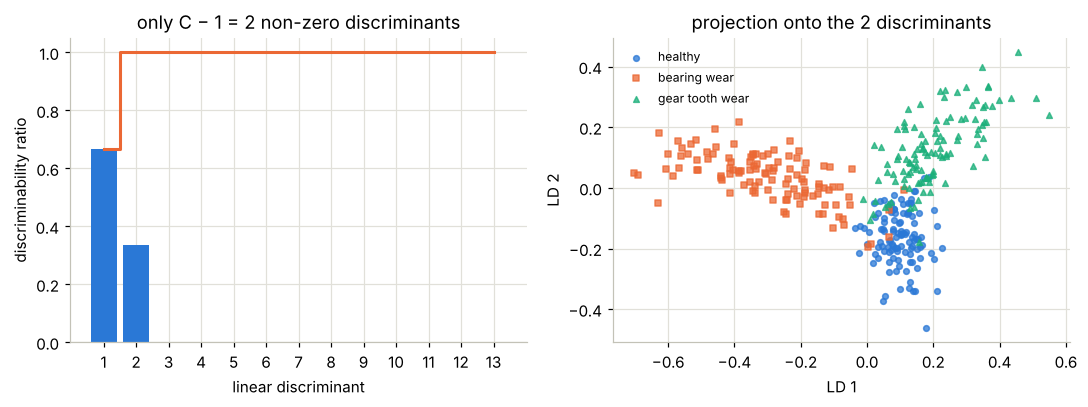

In [8]:
d = X_train_std.shape[1]
mean_vecs = [X_train_std[y_train == c].mean(axis=0) for c in range(3)]
S_W = sum(np.cov(X_train_std[y_train == c].T) for c in range(3))
m_all = X_train_std.mean(axis=0)
S_B = sum((y_train == c).sum() * np.outer(mv - m_all, mv - m_all) for c, mv in enumerate(mean_vecs))

ev, evec = np.linalg.eig(np.linalg.inv(S_W) @ S_B)
ev, evec = ev.real, evec.real
order = np.argsort(ev)[::-1]; ev, evec = ev[order], evec[:, order]
disc = ev / ev.sum()
print("discriminability ratios:", disc.round(4))

W_lda = evec[:, :2]
Z_lda = X_train_std @ W_lda
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].bar(range(1, 14), disc, color=BLUE); ax[0].step(range(1, 14), np.cumsum(disc), where="mid", color=ORANGE, lw=2)
ax[0].set_xlabel("linear discriminant"); ax[0].set_ylabel("discriminability ratio"); ax[0].set_xticks(range(1, 14))
ax[0].set_title("only C − 1 = 2 non-zero discriminants")
for c, m in zip(range(3), ["o", "s", "^"]):
    ax[1].scatter(Z_lda[y_train == c, 0], Z_lda[y_train == c, 1], s=14, marker=m,
                  color=CLASS_COLORS[c], alpha=0.75, label=FAULT_NAMES[c])
ax[1].set_xlabel("LD 1"); ax[1].set_ylabel("LD 2"); ax[1].legend(fontsize=8)
ax[1].set_title("projection onto the 2 discriminants")
plt.tight_layout(); savefig("ch05_lda_manual"); plt.show()

Compared with the PCA scatter, the three conditions now form three much tighter groups: LDA
spends its two dimensions on exactly what separates them.

---
## 5. LDA in scikit-learn; PCA vs LDA as preprocessing

The practical question: if a downstream classifier may only see **two** numbers per recording
(say, to fit on a small embedded controller), should they come from PCA or LDA?

In [9]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
pipes = {
    "all 13 features":   make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "2 PCA components":  make_pipeline(StandardScaler(), PCA(2), LogisticRegression()),
    "2 LDA components":  make_pipeline(StandardScaler(), LDA(n_components=2), LogisticRegression()),
    "2 raw features (best pair: e_bearing, e_sideband)":
        make_pipeline(StandardScaler(), LogisticRegression()),
}
pair = [GEAR_FEATURES.index("e_bearing"), GEAR_FEATURES.index("e_sideband")]
rows = []
for name, p in pipes.items():
    Xtr = X_train[:, pair] if name.startswith("2 raw") else X_train
    Xte = X_test[:, pair] if name.startswith("2 raw") else X_test
    s = cross_val_score(p, Xtr, y_train, cv=cv)
    rows.append(dict(inputs=name, cv_acc=s.mean(), cv_std=s.std(), test_acc=p.fit(Xtr, y_train).score(Xte, y_test)))
pd.DataFrame(rows).set_index("inputs").round(3)

,cv_acc,cv_std,test_acc
inputs,,,
all 13 features,0.935,0.015,0.944
2 PCA components,0.860,0.038,0.840
2 LDA components,0.929,0.017,0.903
"2 raw features (best pair: e_bearing, e_sideband)",0.872,0.023,0.889


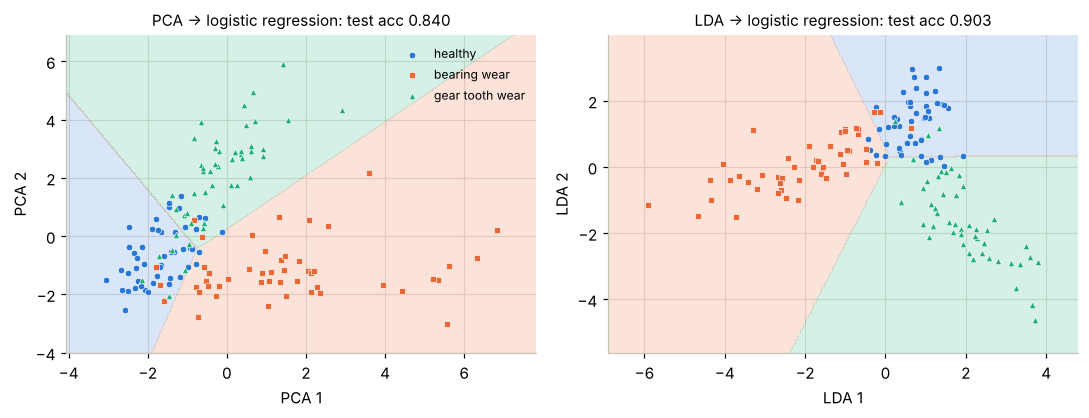

In [10]:
from matplotlib.colors import ListedColormap

fig, axes = plt.subplots(1, 2, figsize=(10, 3.9))
for ax, (name, red) in zip(axes, [("PCA", PCA(2)), ("LDA", LDA(n_components=2))]):
    red.fit(X_train_std, y_train)
    Zt = red.transform(X_test_std)
    clf = LogisticRegression().fit(red.transform(X_train_std), y_train)
    xx, yy = np.meshgrid(np.linspace(Zt[:, 0].min() - 1, Zt[:, 0].max() + 1, 300),
                         np.linspace(Zt[:, 1].min() - 1, Zt[:, 1].max() + 1, 300))
    ax.contourf(xx, yy, clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape),
                levels=[-0.5, 0.5, 1.5, 2.5], cmap=ListedColormap(CLASS_COLORS), alpha=0.18)
    for c, m in zip(range(3), ["o", "s", "^"]):
        ax.scatter(Zt[y_test == c, 0], Zt[y_test == c, 1], s=18, marker=m, color=CLASS_COLORS[c],
                   edgecolor="white", lw=0.4, label=FAULT_NAMES[c])
    ax.set_title(f"{name} → logistic regression: test acc {clf.score(Zt, y_test):.3f}", fontsize=10)
    ax.set_xlabel(f"{name} 1"); ax.set_ylabel(f"{name} 2")
axes[0].legend(fontsize=8)
plt.tight_layout(); savefig("ch05_pca_vs_lda"); plt.show()

With only two numbers per recording, **LDA keeps almost all of the full model's accuracy, PCA
loses a good part of it**, and the best hand-picked pair of raw sensors sits in between. That is
the general rule:

* **PCA** is unsupervised: use it to visualise, de-noise, or compress when you have *no labels*
  or when the downstream task is not yet known.
* **LDA** is supervised: when you do have labels and the goal is classification, it compresses
  *for that goal*. It assumes roughly Gaussian classes with similar covariance and can give at
  most $C-1$ components.

Both are **linear**. For curved structure the book's original chapter also covers kernel PCA;
in practice t-SNE or UMAP (for visualisation) and autoencoders (neural networks, later in the book) fill that role today.

---
## 6. k-means on a robot cell's cycle log

A palletising robot handles three product variants, but the cell controller does not log which
one was on the conveyor. Every cycle it does log the **cycle time** and the **energy drawn**
by the robot. Can we recover the variants — the cell's **operating modes** — from those two
numbers alone? There are no labels, so this is **clustering**.

(450, 2)


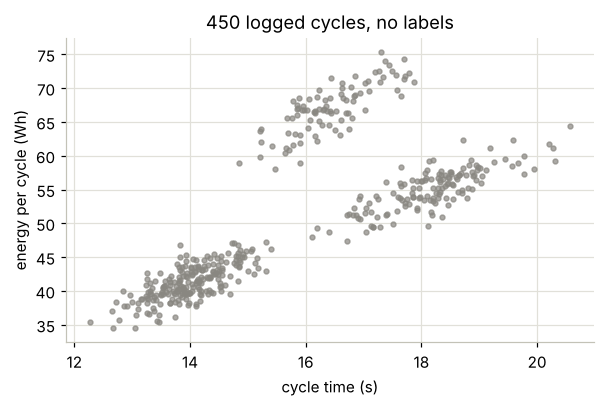

In [11]:
def make_cycle_log(seed=8):
    rng = np.random.default_rng(seed)
    #          n    time mean, sd   energy per s,  sd   (heavier boxes -> more energy per second)
    spec = [(220, 14.0, 0.55, 2.95, 0.10),     # variant A: light boxes, short path
            (140, 18.2, 0.75, 3.05, 0.10),     # variant B: same boxes, higher pallet pattern
            (90,  16.4, 0.65, 4.10, 0.12)]     # variant C: heavy boxes
    T, E, lab = [], [], []
    for k, (n, tm, ts, pm, ps) in enumerate(spec):
        t = rng.normal(tm, ts, n)
        e = t * rng.normal(pm, ps, n) + rng.normal(0, 1.2, n)      # Wh, roughly time x power
        T.append(t); E.append(e); lab.append(np.full(n, k))
    df = pd.DataFrame(dict(cycle_time_s=np.concatenate(T), energy_Wh=np.concatenate(E),
                           variant=np.concatenate(lab)))
    return df.sample(frac=1.0, random_state=seed).reset_index(drop=True)


cycles = make_cycle_log()
Xc = cycles[["cycle_time_s", "energy_Wh"]].to_numpy()
true_variant = cycles["variant"].to_numpy()          # hidden; used only to check at the end
print(Xc.shape)
fig, ax = plt.subplots(figsize=(5.6, 3.8))
ax.scatter(Xc[:, 0], Xc[:, 1], s=10, color=MUTED, alpha=0.7)
ax.set_xlabel("cycle time (s)"); ax.set_ylabel("energy per cycle (Wh)")
ax.set_title(f"{len(Xc)} logged cycles, no labels")
plt.tight_layout(); savefig("ch05_cycles_raw"); plt.show()

### 6.1 The algorithm

k-means looks for $k$ centroids $\boldsymbol\mu_1\dots\boldsymbol\mu_k$ that minimise the
**within-cluster sum of squared errors** (SSE, also called *inertia*)
$$\text{SSE} = \sum_{i=1}^n \min_j \lVert\mathbf x^{(i)} - \boldsymbol\mu_j\rVert^2 .$$
It alternates two steps until the centroids stop moving:

1. **Assign** each point to its nearest centroid.
2. **Update** each centroid to the mean of the points assigned to it.

Each step can only lower the SSE, so the loop converges — but only to a *local* minimum, which
depends on the starting centroids.

Distances again: cycle time spans a few seconds, energy tens of Wh. We **standardise** first.

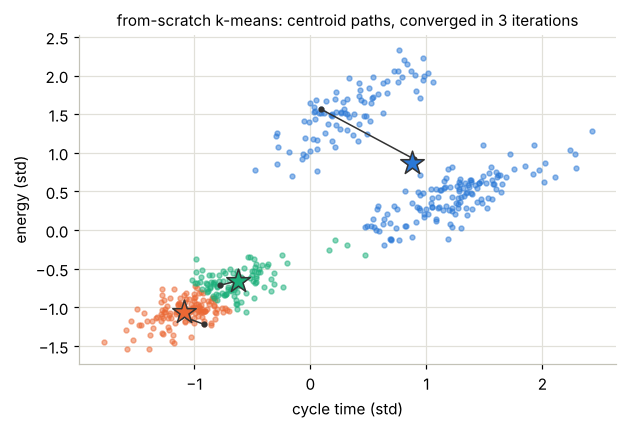

In [12]:
class KMeansScratch:
    """Plain k-means (Lloyd's algorithm) with random initial centroids drawn from the data."""

    def __init__(self, k=3, max_iter=100, tol=1e-6, seed=0):
        self.k, self.max_iter, self.tol, self.seed = k, max_iter, tol, seed

    def fit(self, X, keep_history=False):
        rng = np.random.default_rng(self.seed)
        self.centroids_ = X[rng.choice(len(X), self.k, replace=False)]
        self.history_ = [self.centroids_.copy()]
        for it in range(self.max_iter):
            d = np.linalg.norm(X[:, None, :] - self.centroids_[None, :, :], axis=2)
            self.labels_ = d.argmin(axis=1)                                     # assign
            new = np.array([X[self.labels_ == j].mean(axis=0) if np.any(self.labels_ == j)
                            else self.centroids_[j] for j in range(self.k)])    # update
            shift = np.linalg.norm(new - self.centroids_)
            self.centroids_ = new
            self.history_.append(new.copy())
            if shift < self.tol:
                break
        self.n_iter_ = it + 1
        self.inertia_ = ((X - self.centroids_[self.labels_]) ** 2).sum()
        return self


sc_c = StandardScaler().fit(Xc)
Xc_std = sc_c.transform(Xc)
km0 = KMeansScratch(k=3, seed=3).fit(Xc_std)
H = np.array(km0.history_)

fig, ax = plt.subplots(figsize=(5.8, 4))
for j in range(3):
    ax.scatter(Xc_std[km0.labels_ == j, 0], Xc_std[km0.labels_ == j, 1], s=10, color=CLASS_COLORS[j], alpha=0.5)
    ax.plot(H[:, j, 0], H[:, j, 1], "-o", color="#333", ms=3, lw=1)
    ax.scatter(*H[-1, j], marker="*", s=260, color=CLASS_COLORS[j], edgecolor="#333", zorder=5)
ax.set_xlabel("cycle time (std)"); ax.set_ylabel("energy (std)")
ax.set_title(f"from-scratch k-means: centroid paths, converged in {km0.n_iter_} iterations", fontsize=10)
plt.tight_layout(); savefig("ch05_kmeans_scratch"); plt.show()

### 6.2 Bad starts, and k-means++

Run the plain algorithm from many random starts and the final SSE is not always the same:
some starts get stuck with two centroids in one true group and one centroid straddling two
others. **k-means++** fixes most of this by choosing initial centroids that are spread out —
each new one drawn with probability proportional to its squared distance from the nearest
centroid already chosen. scikit-learn uses it by default and also runs several starts
(`n_init`) and keeps the best.

In [13]:
from sklearn.cluster import KMeans

sse_random = [KMeansScratch(k=3, seed=s).fit(Xc_std).inertia_ for s in range(50)]
sse_pp = [KMeans(3, init="k-means++", n_init=1, random_state=s).fit(Xc_std).inertia_ for s in range(50)]
best = min(sse_random + sse_pp)
print(f"random init : {np.mean(np.isclose(sse_random, best, rtol=1e-3)):.0%} of 50 runs reach the best SSE ({best:.1f})")
print(f"k-means++   : {np.mean(np.isclose(sse_pp, best, rtol=1e-3)):.0%} of 50 runs reach the best SSE")
print(f"worst random-init SSE: {max(sse_random):.1f}")

random init : 52% of 50 runs reach the best SSE (93.2)
k-means++   : 98% of 50 runs reach the best SSE
worst random-init SSE: 186.1


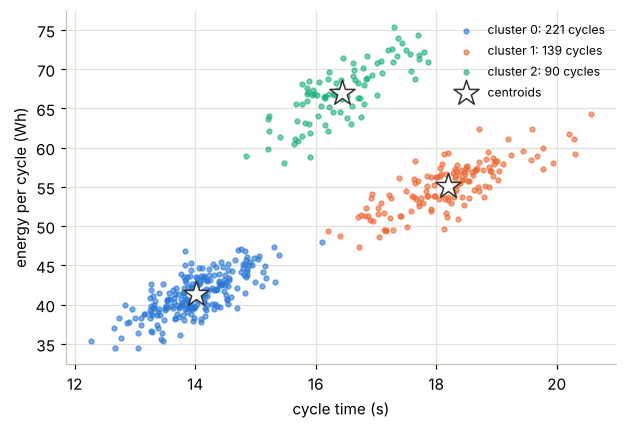

   cycle_time_s  energy_Wh
0          14.0       41.4
1          18.2       55.1
2          16.4       67.0


In [14]:
km = KMeans(n_clusters=3, n_init=10, random_state=0).fit(Xc_std)
centers = sc_c.inverse_transform(km.cluster_centers_)

fig, ax = plt.subplots(figsize=(5.8, 4))
for j in range(3):
    ax.scatter(Xc[km.labels_ == j, 0], Xc[km.labels_ == j, 1], s=10, color=CLASS_COLORS[j], alpha=0.6,
               label=f"cluster {j}: {np.sum(km.labels_ == j)} cycles")
ax.scatter(centers[:, 0], centers[:, 1], marker="*", s=300, color="white", edgecolor="#333", zorder=5,
           label="centroids")
ax.set_xlabel("cycle time (s)"); ax.set_ylabel("energy per cycle (Wh)"); ax.legend(fontsize=8)
plt.tight_layout(); savefig("ch05_kmeans_sklearn"); plt.show()
print(pd.DataFrame(centers, columns=["cycle_time_s", "energy_Wh"]).round(1))

Because this is a simulation we can peek at the hidden variant labels and check. The
**adjusted Rand index** (ARI) compares two labellings regardless of how clusters are numbered:
1 is perfect agreement, 0 is chance.

In [15]:
from sklearn.metrics import adjusted_rand_score
print(f"ARI, k-means on standardised data : {adjusted_rand_score(true_variant, km.labels_):.3f}")
km_raw = KMeans(3, n_init=10, random_state=0).fit(Xc)
print(f"ARI, k-means on raw (unscaled) data: {adjusted_rand_score(true_variant, km_raw.labels_):.3f}")
print(pd.crosstab(true_variant, km.labels_, rownames=["hidden variant"], colnames=["cluster"]))

ARI, k-means on standardised data : 0.992
ARI, k-means on raw (unscaled) data: 0.939
cluster           0    1   2
hidden variant              
0               220    0   0
1                 1  139   0
2                 0    0  90


---
## 7. How many clusters?

In practice nobody tells you $k$. Two standard diagnostics:

* **Elbow method** — plot SSE against $k$. SSE always falls as $k$ grows; look for the point
  where adding a cluster stops paying off.
* **Silhouette analysis** — for each point, $a$ = mean distance to points in its own cluster,
  $b$ = mean distance to points in the nearest *other* cluster, and
  $$s = \frac{b-a}{\max(a,b)}\in[-1,1].$$
  Close to 1: well inside its cluster. Near 0: on a border. Negative: probably in the wrong
  cluster. The average silhouette is a single score to compare values of $k$.

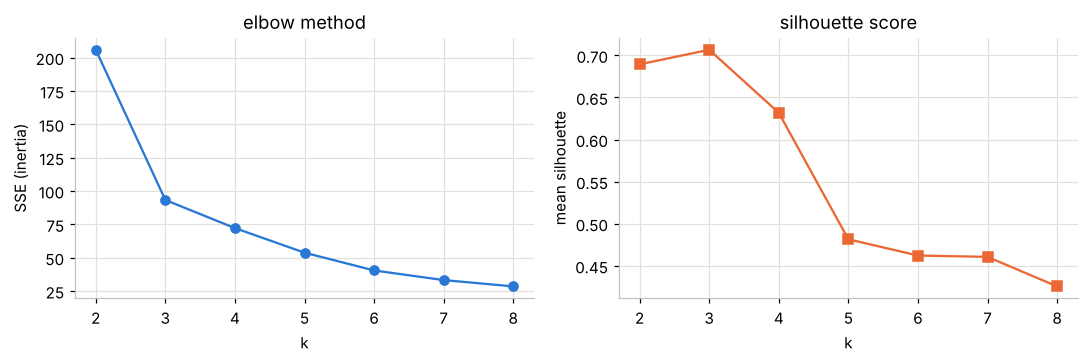

best k by silhouette: 3


In [16]:
from sklearn.metrics import silhouette_score, silhouette_samples

ks = range(2, 9)
sse = [KMeans(k, n_init=10, random_state=0).fit(Xc_std).inertia_ for k in ks]
sil = [silhouette_score(Xc_std, KMeans(k, n_init=10, random_state=0).fit_predict(Xc_std)) for k in ks]

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(ks, sse, "o-", color=BLUE); ax[0].set_xlabel("k"); ax[0].set_ylabel("SSE (inertia)"); ax[0].set_title("elbow method")
ax[1].plot(ks, sil, "s-", color=ORANGE); ax[1].set_xlabel("k"); ax[1].set_ylabel("mean silhouette"); ax[1].set_title("silhouette score")
plt.tight_layout(); savefig("ch05_elbow_silhouette"); plt.show()
print("best k by silhouette:", list(ks)[int(np.argmax(sil))])

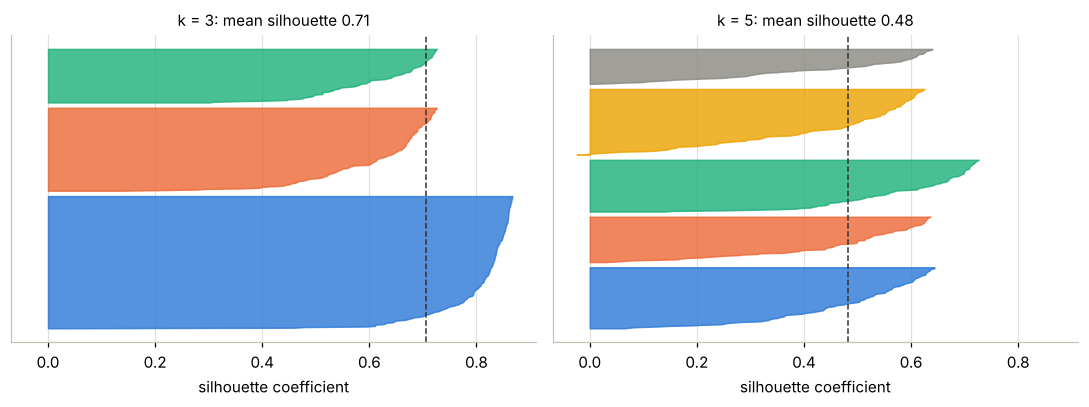

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True)
for ax, k in zip(axes, [3, 5]):
    lab = KMeans(k, n_init=10, random_state=0).fit_predict(Xc_std)
    s = silhouette_samples(Xc_std, lab)
    lower = 0
    for j in range(k):
        sj = np.sort(s[lab == j])
        ax.fill_betweenx(np.arange(lower, lower + len(sj)), 0, sj,
                         color=(CLASS_COLORS + [YELLOW, MUTED])[j], alpha=0.8)
        lower += len(sj) + 8
    ax.axvline(s.mean(), color="#333", ls="--", lw=1)
    ax.set_title(f"k = {k}: mean silhouette {s.mean():.2f}", fontsize=10); ax.set_yticks([])
    ax.set_xlabel("silhouette coefficient")
plt.tight_layout(); savefig("ch05_silhouette_plots"); plt.show()

With $k = 3$ the silhouette coefficients are high across all three clusters and almost no
point is near zero; with $k = 5$ the true groups are cut in pieces, the coefficients drop in
every cluster, a few points go negative, and the mean falls. Both
diagnostics point to three operating modes — matching the three product variants we hid.

**Where k-means struggles.** It assumes roughly round, similarly sized clusters and assigns
*every* point to some cluster. Elongated or nested shapes, and data with outliers that should
belong to *no* cluster (an operator stop, a jam), need density-based methods. The **DBSCAN**
notebooks that accompany this chapter apply exactly that to condition monitoring of a CNC
spindle, robot joint torques and wind-turbine SCADA data.

---
## Summary

* Correlated sensors carry fewer independent pieces of information than their count suggests.
* **PCA**: unsupervised, finds directions of maximum variance; good for visualisation,
  compression and de-noising; components are interpretable through their loadings.
* **LDA**: supervised, finds directions of maximum class separation; at most $C-1$ of them;
  the better choice when compressing *for classification*.
* **k-means**: minimises within-cluster SSE by alternating assign/update; standardise first,
  use k-means++ with several restarts, choose $k$ with elbow and silhouette.

## Exercises

1. Keep enough principal components for 95 % of the variance and train logistic regression on
   them. How close do you get to the all-feature accuracy, with how many components?
2. Fit PCA on the **healthy** recordings only, then compute each test recording's
   reconstruction error. Does a high error flag faulty units? (This is a classic unsupervised
   anomaly detector.)
3. Drop the label-dependent feature subset (`e_bearing`, `e_sideband`) and repeat §5. Which
   method suffers more, PCA or LDA, and why?
4. Add a fourth logged variable — the robot's peak joint-3 torque, higher for variant B because
   of the taller pallet pattern — and recluster. Does the ARI improve?
5. Add 20 "jam" cycles (cycle time 30–60 s, low energy) to the log. What does k-means do with
   them? Try `sklearn.cluster.DBSCAN` instead.